# Why RT-DETR:

## Handling varying object counts

Our dataset contains images of with varying density of objects. So we must select a model that can handle different object counts and spatial arrangements effectively.

## Replacing NMS for overlapping boxes

DETR variants excel in dense object detection scenarios, due primarily to the replacement of Non-Maximum Suppression (NMS), which is traditionally used to remove overlapping predictions via Intersection over Union (IoU) thresholds and priority. With Transformer-based bi-parite matching, where the model must explicitly learn to associate predicted objects with ground truth objects, even in crowded scenes and learns to avoid discarding overlapping predictions prematurely.

The object queries are learnable embeddings that directly guide the decoder in predicting object locations and classes, allowing the model to focus on specific regions of the image and handle overlapping objects more effectively, as these object queries learn to adapt to different object densities and spatial arrangements during training. In RT-DETR, this mechanism was further improved by switching out the static learnable object queries with dynamic object queries that are generated based on the input image's encoder features.

Attention in general performs well in capturing long-range dependencies and contextual information within an image, which is particularly beneficial for dense object detection where objects may be closely packed and overlapping. Where the encoder captures global context and relationships between different regions of the image, the decoder can leverage this information through the object queries to make more informed predictions about object locations and classes, even in challenging scenarios with high object density.

## Fixed queries under class imbalance

Our dataset also has a severe class imbalance, with some object categories being significantly underrepresented compared to others alongside this 58 different object categories are present, making it crucial for the model to effectively handle many class distinctions and class imbalance.

DETR's fixed `N` number of object queries helps mitigate 'anchor flooding' where two many candidate predictions compete for the same ground truth object, helping ensure that even underrepresented classes have a fair chance of being detected and reducing the likelihood of missing objects due to excessive competition among predictions. Furthermore, again, the nature of attention (self attention at the encoder and self + cross attention at the decoder) allows the model to effectively leverage contextual information, which can help improve detection performance for underrepresented classes by considering the broader scene context rather than relying solely on local features, even across 58 different object categories with significant class imbalance.

## Anchor-free boxes for small objects

Our dataset contains mostly small, distinct objects and they can overlap marginally.


A prediction anchor or 'anchor box' is a predefined reference box used in anchor-based object detection methods to predict the location and size of objects in an image. These are of a fixed size and aspect ratio.

Instead of relying on predefined anchor boxes, anchor-free methods like RT-DETR predict normalized bounding box coordinates and dimensions (`x, y, width, height`) directly from the image features (actioned by the FFN prediction heads), allowing the model to adapt more flexibly to varying object sizes and positions without being constrained by fixed anchor shapes. Bounding boxes can be any size and aspect ratio, providing greater flexibility in detecting objects of different shapes and scales, like our small, distinct, objects.


In [19]:
!pip install -q transformers iterative-stratification

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import pickle as pkl
from PIL import Image, ImageOps
from torchvision.transforms import v2 as transforms
from torch.utils.data import DataLoader
from dotenv import find_dotenv, load_dotenv
import os
from pathlib import Path
from typing import Any
from transformers import RTDetrForObjectDetection
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# load in data_dir environment variable
load_dotenv(find_dotenv(usecwd=True))
data_dir = Path(os.environ["DATA_PATH"])

In [23]:
df = pd.read_pickle(data_dir / 'processed_samples.pkl')
print(df[0])

('drafter_-1/images/C-10_D1_P1.jpg', None, (('junction', (1341, 654, 1381, 690)), ('junction', (1075, 896, 1109, 930)), ('junction', (1743, 657, 1781, 695)), ('junction', (1548, 1016, 1582, 1048)), ('junction', (1094, 1361, 1126, 1395)), ('junction', (1360, 1681, 1404, 1723)), ('junction', (1349, 886, 1389, 920)), ('junction', (1760, 1661, 1798, 1699)), ('junction', (1089, 1036, 1125, 1072)), ('resistor', (1067, 1111, 1138, 1222)), ('junction', (1076, 680, 1108, 710)), ('junction', (1561, 1479, 1595, 1513)), ('junction', (1162, 1683, 1192, 1717)), ('junction', (1344, 1024, 1386, 1060)), ('junction', (1351, 1352, 1391, 1388)), ('junction', (1539, 883, 1573, 915)), ('resistor', (1049, 755, 1113, 849)), ('resistor', (1330, 1111, 1402, 1197)), ('resistor', (1341, 1559, 1431, 1663)), ('resistor', (1142, 1565, 1227, 1668)), ('junction', (1155, 1508, 1184, 1533)), ('junction', (1561, 1353, 1590, 1380)), ('voltage.ac', (1322, 1225, 1406, 1331)), ('voltage.ac', (1054, 1244, 1135, 1329)), ('resi

In [24]:
print(df[1])

('drafter_-1/images/C-10_D1_P2.jpg', None, (('junction', (507, 919, 543, 957)), ('junction', (453, 1568, 489, 1606)), ('junction', (556, 623, 596, 663)), ('junction', (896, 701, 938, 743)), ('junction', (772, 2066, 826, 2120)), ('junction', (1336, 857, 1382, 907)), ('junction', (859, 1004, 895, 1046)), ('junction', (792, 1624, 826, 1660)), ('junction', (823, 1181, 867, 1225)), ('junction', (1077, 1064, 1115, 1102)), ('junction', (507, 2040, 545, 2080)), ('junction', (1064, 1237, 1100, 1273)), ('junction', (1230, 2086, 1268, 2126)), ('junction', (1033, 1665, 1069, 1697)), ('junction', (1020, 1830, 1058, 1866)), ('junction', (494, 1110, 536, 1152)), ('resistor', (766, 1906, 856, 2040)), ('junction', (782, 1804, 830, 1856)), ('voltage.ac', (758, 1448, 861, 1581)), ('voltage.ac', (401, 1392, 522, 1506)), ('junction', (514, 1786, 554, 1817)), ('resistor', (485, 1867, 600, 2007)), ('resistor', (838, 817, 941, 976)), ('resistor', (495, 711, 587, 851)), ('resistor', (776, 1290, 882, 1420)), ('

In [25]:
for item in df: 
    for box in item[2]: # boxes
        print(box[1:]) # box coordinates
        print(box[0]) # label
        break
    break


((1341, 654, 1381, 690),)
junction


## Categorical Encoding (Label Encoding)

`LabelEncoder` was used to convert categorical labels (class labels, e.g diode) into a numerical format that can be used by machine learning algorithms. Label Encoder converts each unique class label into an integer value, starting from 0 having sorted the class labels into alphabetical order. So if the class labels are ["diode", "resistor", "capacitor"], Label Encoder will convert them to [1, 2, 0] respectively.

The important part here is, one-hot was not used because Cross Entropy Loss in PyTorch expects class indices as targets, not one-hot encoded vectors. Using Label Encoding ensures that the target labels are in the correct format for the loss function we are planning to utilize.

No need for ordinal encoding as our classes do not have an inherent order.

In [26]:
from sklearn.preprocessing import LabelEncoder

# cross entropy loss will expect class indices, not one hot encoded labels and its easier to work with class indices instead of one hot encoded labels for this task anyways.
# label encoder gives us a way to convert the class labels to class indices
label_encoder = LabelEncoder()
label_encoder.fit([label for _, _, boxes in df for label, _ in boxes]) # fit the label encoder on all the labels in the dataset

processed_samples = [
    (
        image,
        segment,
        tuple((int(label_encoder.transform([label])[0]), box) for label, box in boxes), # label encoder will return a numpy array, we pull the first (and only) element to get the class index for the box
        # we also keep the label and the box together in a tuple so they are not separated per image
    )
    for image, segment, boxes in df
]

In [27]:
class ObjectDetectionDataset():
    def __init__(self, list_of_tuples, transform=None):
        self.list_of_tuples = list_of_tuples
        self.transform = transform

    def _extract_boxes(self, boxes): # extract the boxes and labels from the list of tuples
        boxes_labels = [box for box in boxes if box is not None] # remove any None values
        boxes = [box[1] for box in boxes_labels] # box coordinates, without the label
        labels = [box[0] for box in boxes_labels] # extract the label from the box
        return boxes, labels

    def __len__(self):
        return len(self.list_of_tuples)    

    def __getitem__(self, idx):
        sample = self.list_of_tuples[idx] # get the sample at the given index
        image, _, boxes = sample # unpack the sample
        image = ImageOps.exif_transpose(Image.open(data_dir / image)).convert("RGB") # rotate the image if necessary and convert to RGB instead of RGBA so we have 3 channels
        # pull boxes from the list of tuples
        boxes, labels = self._extract_boxes(boxes) # extract the boxes and labels from the list of tuples
        # convert boxes to tensor
        boxes = torch.tensor(boxes, dtype=torch.float32) # convert the boxes to a tensor
        # convert labels to tensor
        labels = torch.tensor(labels, dtype=torch.int64) # convert the labels to a tensor (LongTensor expected by loss function)

        if self.transform is not None:
            image, boxes = self.transform(image, boxes)

        return image, boxes, labels



## Data Preprocessing

In [28]:
from torchvision.tv_tensors import BoundingBoxes
import torchvision

standard_transforms = transforms.Compose([
    transforms.ToImage(), # convert the image to a channel first tensor (C, H, W)
    transforms.Resize((640, 640)), # resize the image to 640x640, scaling the bounding boxes accordingly
    transforms.ToDtype(dtype=torch.float32, scale=True), # convert the image to float32 and scale the pixel values to be between 0 and 1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) #Normalize to the same as imagenet
])

def preprocess(image, boxes): # only takes in images, boxes no labels
    # Resize scales BoundingBoxes with the image, using a separate factor for width and height, so they sit in the same place in the image after resizing.
    # ToDtype and Normalize only change pixel values, so the boxes pass through.
    width, height = image.size
    boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4) # convert boxes to tensor with shape (N, 4) (4 = x1, y1, x2, y2)
    boxes = BoundingBoxes(boxes, format="XYXY", canvas_size=(height, width)) # convert boxes to BoundingBoxes object
    images, boxes = standard_transforms(image, boxes) # apply the standard transforms to the image and boxes
    # With DETR, X and Y coordinates are based on the distance from the top left corner of the image to the center point of the box
    boxes = torchvision.ops.box_convert(boxes, in_fmt="xyxy", out_fmt="cxcywh") # convert X and Y corner coordinates to center coordinates and store width and height
    boxes = boxes / 640  # DETR requires we turn our center coordinates and width and height are normalized (between 0 and 1) as a proportion of the image size.
    # So both the distances (x, y) and the width and height are between 0 and 1 based on the rezied image size.
    return images, boxes


In [29]:
# test the dataset
dataset = ObjectDetectionDataset(processed_samples, transform=preprocess)
print(len(dataset))
print(dataset[0])

3293
(Image([[[-2.0152, -2.0323, -2.0323,  ..., -0.9363, -0.9534, -0.9363],
        [-2.0665, -2.0494, -2.0323,  ..., -0.9020, -0.9363, -0.9363],
        [-2.0665, -2.0494, -2.0323,  ..., -0.9020, -0.9192, -0.9192],
        ...,
        [ 0.5193,  0.4851,  0.4851,  ..., -0.9192, -0.9363, -0.9534],
        [ 0.5022,  0.4851,  0.4679,  ..., -0.9192, -0.9192, -0.9192],
        [ 0.4851,  0.4679,  0.4679,  ..., -0.9192, -0.9020, -0.9020]],

       [[-1.8957, -1.9307, -1.9482,  ..., -1.2829, -1.3004, -1.2829],
        [-1.9482, -1.9307, -1.9482,  ..., -1.2479, -1.2829, -1.2829],
        [-1.9832, -1.9657, -1.9482,  ..., -1.2479, -1.2654, -1.2654],
        ...,
        [ 0.5903,  0.5553,  0.5553,  ..., -1.2654, -1.2829, -1.3004],
        [ 0.5728,  0.5553,  0.5378,  ..., -1.2654, -1.2654, -1.2654],
        [ 0.5553,  0.5378,  0.5378,  ..., -1.2829, -1.2479, -1.2479]],

       [[-1.7173, -1.7347, -1.7173,  ..., -1.3164, -1.3339, -1.3164],
        [-1.7347, -1.7173, -1.7173,  ..., -1.2816, -1.

## Data Split

In [30]:
# limited dataset size to 1000 samples due to computational constraints (stratified sampling to ensure class distribution matches original dataset)
# We can't use Sklearn's train_test_split with stratification because each image contains multiple classes across multiple boxes
test_split = 0.2
valid_split = 0.1 # newly limited data means we can't allocate a large validation set
train_split = 1 - test_split - valid_split

dataset_limit = 1000 # images kept before the split

def stratified_split(samples, fractions, limit=None, seed=42):
    # Iterative stratification gives the kept images, and each split, the same share of every class (stratified)
    n_classes = max(label for _, _, boxes in samples for label, _ in boxes) + 1 # one column per class
    classes = np.zeros((len(samples), n_classes), dtype=int) # one row per image
    for index, (_, _, boxes) in enumerate(samples):
        for label, _ in boxes:
            classes[index, label] = 1 # this image contains this class

    indices = np.arange(len(samples)) # each image's place in the full dataset
    if limit is not None and limit < len(samples):
        splitter = MultilabelStratifiedShuffleSplit( # keep limit images, the rest are left out of every split (test_size = images left out of the splits)
            n_splits=1, train_size=limit, test_size=len(samples) - limit, random_state=seed
        ) # one division, and seed makes it the same every run
        kept, _ = next(splitter.split(np.zeros((len(samples), 1)), classes)) # the zeros stand in for the images, the split only looks at the class matrix
        indices, classes = indices[kept], classes[kept]

    train_fraction, valid_fraction, test_fraction = fractions
    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test_fraction, random_state=seed) # peel off the test share (0.2)
    rest, test = next(splitter.split(np.zeros((len(indices), 1)), classes)) # rest is what is left for train and validation
    valid_fraction_of_rest = valid_fraction / (train_fraction + valid_fraction) # validation's share of what is left (0.1 / 0.8)
    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=valid_fraction_of_rest, random_state=seed) # peel validation off the remainder
    train, valid = next(splitter.split(np.zeros((len(rest), 1)), classes[rest])) # same kind of split, now only on the leftover images
    return indices[rest][train], indices[rest][valid], indices[test] # turn these positions back into places in the full dataset

train_indices, valid_indices, test_indices = stratified_split(
    processed_samples, [train_split, valid_split, test_split], limit=dataset_limit
)
train_dataset = torch.utils.data.Subset(dataset, train_indices) # stratified train split
valid_dataset = torch.utils.data.Subset(dataset, valid_indices) # stratified validation split
test_dataset = torch.utils.data.Subset(dataset, test_indices) # stratified test split
print(len(train_dataset), len(valid_dataset), len(test_dataset))


702 104 197


In [31]:
# collate_fn functions create a batch of data from a list of samples from __getitem__ within the dataset object.
def collate_fn(batch):
    images, boxes, labels = zip(*batch) # unzip the batch into images, boxes and labels
    images = torch.stack(images) # (batch, C, H, W). Pixels only, boxes and labels are not stored in this tensor.
    # One tensor per image. An image with X objects has boxes of shape (X, 4), each row x1, y1, x2, y2,
    # and labels of shape (X,), the class index for that row. X differs per image, so neither list is stacked (merged) into a tensor because the contents of the lists are different sizes across the batch.
    boxes = list(boxes) # list of (X, 4) tensors, one per image
    labels = list(labels) # list of (X,) tensors, one per image, same X as that image's boxes
    targets = [ # DETR requires a list of dictionaries, one per image with each images boxes and class labels
        {"class_labels": class_ids, "boxes": box_tensor}
        for class_ids, box_tensor in zip(labels, boxes) # zips this batches class indices with the boxes so we can iterate over them together, keeping the class indices and there respective boxes together
    ]
    return images, targets



train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn) # create a dataloader for the train set
valid_loader = DataLoader(valid_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn) # create a dataloader for the valid set
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn) # create a dataloader for the test set

In [32]:
images, targets = next(iter(train_loader))

In [33]:
targets[0] # target boxes with their class indices for the first image in the batch

{'class_labels': tensor([38, 38, 38, 38, 38,  4,  4, 20, 20,  8, 20, 20, 20, 20, 20, 20, 20, 20,
         20, 20, 20, 20, 20, 20, 20, 20, 20,  8, 20,  5, 43, 53, 20]),
 'boxes': tensor([[0.5606, 0.5231, 0.0407, 0.1040],
         [0.6422, 0.5020, 0.0401, 0.0977],
         [0.5689, 0.7248, 0.0434, 0.1147],
         [0.7981, 0.8028, 0.0618, 0.0565],
         [0.8630, 0.5043, 0.0412, 0.1013],
         [0.4280, 0.5159, 0.0512, 0.0314],
         [0.4350, 0.7158, 0.0518, 0.0323],
         [0.8727, 0.6293, 0.0123, 0.0197],
         [0.2696, 0.8512, 0.0123, 0.0197],
         [0.2612, 0.5343, 0.0512, 0.0681],
         [0.2612, 0.6181, 0.0128, 0.0206],
         [0.6516, 0.6419, 0.0095, 0.0161],
         [0.1777, 0.6271, 0.0134, 0.0224],
         [0.4224, 0.4473, 0.0145, 0.0242],
         [0.1710, 0.2515, 0.0184, 0.0287],
         [0.8752, 0.8037, 0.0123, 0.0206],
         [0.5647, 0.6015, 0.0201, 0.0323],
         [0.4422, 0.8279, 0.0156, 0.0242],
         [0.5776, 0.8140, 0.0173, 0.0251],
      

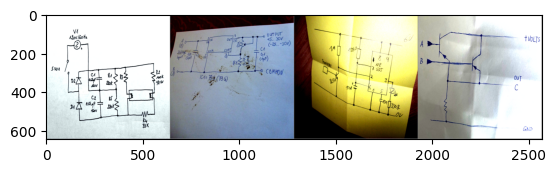

tensor([[0.5606, 0.5231, 0.0407, 0.1040],
        [0.6422, 0.5020, 0.0401, 0.0977],
        [0.5689, 0.7248, 0.0434, 0.1147],
        [0.7981, 0.8028, 0.0618, 0.0565],
        [0.8630, 0.5043, 0.0412, 0.1013],
        [0.4280, 0.5159, 0.0512, 0.0314],
        [0.4350, 0.7158, 0.0518, 0.0323],
        [0.8727, 0.6293, 0.0123, 0.0197],
        [0.2696, 0.8512, 0.0123, 0.0197],
        [0.2612, 0.5343, 0.0512, 0.0681],
        [0.2612, 0.6181, 0.0128, 0.0206],
        [0.6516, 0.6419, 0.0095, 0.0161],
        [0.1777, 0.6271, 0.0134, 0.0224],
        [0.4224, 0.4473, 0.0145, 0.0242],
        [0.1710, 0.2515, 0.0184, 0.0287],
        [0.8752, 0.8037, 0.0123, 0.0206],
        [0.5647, 0.6015, 0.0201, 0.0323],
        [0.4422, 0.8279, 0.0156, 0.0242],
        [0.5776, 0.8140, 0.0173, 0.0251],
        [0.2604, 0.4648, 0.0123, 0.0188],
        [0.5569, 0.4370, 0.0162, 0.0260],
        [0.6575, 0.6777, 0.0095, 0.0161],
        [0.6408, 0.4267, 0.0178, 0.0242],
        [0.3356, 0.2385, 0.0162, 0

In [34]:
from torchvision.utils import make_grid

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

imshow(make_grid(images[:4]))

# show the first batch of boxes
for i in range(4):
    print(targets[i]["boxes"])
    print(targets[i]["class_labels"])

## Model

In [35]:
id2label = {i: str(name) for i, name in enumerate[Any | list | None](label_encoder.classes_)} # id2label is a dictionary that maps the class index to the class name
label2id = {name: i for i, name in id2label.items()} # label2id maps class name back to class indices

model = RTDetrForObjectDetection.from_pretrained(
    "PekingU/rtdetr_r50vd", # resnet50 (CNN backbone)
    num_labels=len(id2label), # number of classes
    id2label=id2label, # maps the class index to the class name (for output predictions clarity)
    label2id=label2id, # saved with the model, so a class name can be mapped back to a class index
    # our class prediction head will have 58 class prediction linear layer output neurons (num_labels does this output neuron adjustment for us), - its not an FFN because its a single layer, with no hidden layers
    # so the class prediction linear layer weights won't load as they were built for a different number of classes, so we ignore them and reinitialize the weights
    # the box prediction head will have 4 box prediction FFN output neurons (center_x, center_y, width, height), so it will load as expected
    ignore_mismatched_sizes=True, 
)

[transformers] You passed `num_labels=58` which is incompatible to the `id2label` map of length `80`.


Loading weights:   0%|          | 0/764 [00:00<?, ?it/s]

[transformers] RTDetrForObjectDetection LOAD REPORT from: PekingU/rtdetr_r50vd
Key                                                 | Status   |                                                                                         
----------------------------------------------------+----------+-----------------------------------------------------------------------------------------
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([58, 256])
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([58])          
model.denoising_class_embed.weight                  | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([81, 256]) vs model:torch.Size([59, 256])
model.enc_score_head.bias                           | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([58])        

## Training Loop

Weight decay is automatically set to 0.01 with AdamW optimizer.

The difference between Adam and AdamW is that AdamW decouples weight decay from the gradient update, which allows for a more effective regularization.

In Adam, weight decay is applied as part of the gradient update, which can interfere with the optimization process. AdamW applies weight decay directly to the parameters (weights, biases and normalization layers), ensuring that the regularization effect is consistent and independent of the gradient updates.

Given we are fine tuning, we will choose a low learning rate to avoid large updates that erode the pre-trained knowledge in the model.

Using a high learning rate during fine tuning can lead to large updates that may overwrite the valuable pre-trained knowledge, resulting in suboptimal performance. This is because large updates can significantly alter the model parameters, diminishing the benefits of pre-training and potentially causing the model to forget previously learned features.

however, for our class-score layers, which are newly added and randomly initialized parameters (weights and biases), this low learning rate may slow down their convergence. Therefore, it is common practice to use a higher learning rate for these layers to ensure they learn effectively while still maintaining a low learning rate for the pre-trained layers to preserve their knowledge.

### class_embed and enc_score_head:

these are the two other layers that are newly initialized. Both relate to the classification aspect of the model. 

The bounding box layers of the model actually fit our detection task because we are also predicting `center_x, center_y, width, and height` for the objects, which aligns with the original DETR's bounding box prediction mechanism. So we can fine tune those layers with a lower learning rate, as they already have pre-trained weights that are relevant to our task.


The six `class_embed` layers (each) takes in the 256 dimensional embeddings from the transformer and transforms / outputs them to class scores for all 58 of our classes, which are then passed to a  sigmoid activation. This allows the model to predict the presence of each class independently. This layer is newly initialized (fresh weights and biases) and therefore may benefit from a higher learning rate during fine-tuning. They are newly initialized because the existing pre-trained model was designed for 80 classes and a different classification task, so the original weights are not directly applicable to our 58-class problem. This `class_embed` layer -> sigmoid combination forms our class prediction head.

`enc_score_head` is one newly initialized layer that performs the same scoring on the encoders embeddings (which are also 256 dimensional), remember that these embeddings are based on a sequenced version of the CNN's output feature maps, so the encoders output can be considered a feature map representation as its spatial structure is preserved in the sequence. This builds the object queries for the decoder by highlighting the most relevant features from the encoder's output to help give the decoder an informative starting point. Being newly initialized, this layer may also benefit from a higher learning rate during fine-tuning to ensure effective learning. This `enc_score_head` is an RT-DETR specific layer, original DETR does not have this component. 

^ This is what allows for that 'further improved by switching out the static learnable object queries with dynamic object queries that are generated based on the input image's encoder features' comment above.

So the encoder outputs that 256-dimensional feature map embeddings to give contextilised embeddings to the decoder, the `enc_score_head` layer scores these embeddings to identify the most relevant features, which are then used to build the object queries for the decoder. This helping that the decoder focuses on the most informative parts of the encoder's output, improving the overall object detection performance.

Each of our object queries is designed to give the decoder an informative starting point based on the encoder's output based on the scores provided by the `enc_score_head`. Each of these queries is then ran through the decoder, which processes the attended features and produces the final class predictions for each query, with `class_embed` generating the class scores for each query (each query was a different starting point for the decoder to attend to specific parts of the encoder's output). These are then passed through a sigmoid activation to give each query a probability for each class.

In order to reach our final class predictions, we take the highest sigmoid scoring class (from the 58) from each of our queries. Queries who's confidence (sigmoid score) is below a certain threshold can be discarded or treated as background, ensuring that only confident predictions in the image are labeled.

In [36]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model.to(device)

# class_embed, enc_score_head, and denoising_class_embed were reinitialized for 58 classes
new_head_names = ("class_embed", "enc_score_head", "denoising_class_embed")
pretrained_params, new_params = [], []
for name, param in model.named_parameters():
    if any(part in name for part in new_head_names):
        new_params.append(param)
    else:
        pretrained_params.append(param)

optimizer = torch.optim.AdamW(
    [
        {"params": pretrained_params, "lr": 1e-5}, # pretrained backbone and box head, lower learning rate so we don't disrupt the learned features too much
        {"params": new_params, "lr": 1e-4}, # reinitialized class-score layers, higher learning rate to allow them to learn quickly
    ],
    weight_decay=1e-4, # RT-DETR weight decay. AdamW's default is 0.01
)

epochs = 40 # ceiling for the number of training epochs, early stopping may halt training sooner

In [37]:
print(f"device {device}")

device cuda


In [38]:
import time

def train_one_epoch(model, loader, optimizer, device, log_every_minutes=5):
    model.train()
    train_loss = 0.0
    last_log = time.monotonic()
    for batch_index, (images, targets) in enumerate(loader, start=1): # iterate over batches of images and targets from the data loader
        images = images.to(device) # move images to the correct device (CPU or GPU)
        targets = [{key: value.to(device) for key, value in target.items()} for target in targets] # move targets to the correct device

        outputs = model(pixel_values=images, labels=targets) # forward pass through the model with the current batch of images and targets
        loss = outputs.loss # bipartite matching loss for DETR (notes in OneNote)

        optimizer.zero_grad() # reset gradients before backpropagation (mini batch, so we calculate gradients for each batch separately)
        loss.backward() # compute gradients for the models parameters based on the current batch loss
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1) # gradient clipping to prevent exploding gradients, help stabilize training
        optimizer.step() # update model parameters based on computed gradients for this batch
        train_loss += loss.item() # accumulate the loss for this batch to compute the average loss for the epoch

        if time.monotonic() - last_log >= log_every_minutes * 60: # print the running cost every X minutes during the epoch (for better monitoring of training progress)
            print(f"batch {batch_index}/{len(loader)}  cost {train_loss / batch_index:.4f}", flush=True)
            last_log = time.monotonic()

    return train_loss / len(loader) # return the average loss for the epoch (full pass through the dataset)

def early_stopping(valid_cost, best_valid_cost, epochs_without_improvement, patience, model, best_model_state):
    if valid_cost < best_valid_cost: # early stopping check: if the validation cost improves, reset the counter
        best_valid_cost = valid_cost # update the best validation cost since it has improved
        epochs_without_improvement = 0
        best_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()} # keep the weights from the lowest validation cost
    else:
        epochs_without_improvement += 1 # increment the counter if no improvement in validation cost
    stop = epochs_without_improvement >= patience # stop if the validation cost has not fallen for `patience` epochs
    return best_valid_cost, epochs_without_improvement, best_model_state, stop

In [39]:
train_costs = []
valid_costs = []
best_valid_cost = float("inf")
epochs_without_improvement = 0
patience = 8 # stop if the validation cost does not fall for this many epochs
best_model_state = None

for epoch in range(epochs): # iterate over the number of training epochs
    train_loss = train_one_epoch(model, train_loader, optimizer, device)

    model.eval() # set the model to evaluation mode
    valid_loss = 0.0
    with torch.no_grad(): # disable gradient computation for validation
        for images, targets in valid_loader: # iterate over validation batches
            images = images.to(device) # move images to the correct device
            targets = [{key: value.to(device) for key, value in target.items()} for target in targets] # move targets to the correct device
            outputs = model(pixel_values=images, labels=targets) # forward pass for validation
            valid_loss += outputs.loss.item() # accumulate validation loss for the current batch

    train_cost = train_loss
    valid_cost = valid_loss / len(valid_loader)
    train_costs.append(train_cost)
    valid_costs.append(valid_cost)
    print(epoch, train_cost, valid_cost) # print the epoch number, training cost, and validation cost at the current epoch

    best_valid_cost, epochs_without_improvement, best_model_state, stop = early_stopping(
        valid_cost, best_valid_cost, epochs_without_improvement, patience, model, best_model_state
    )
    if stop: # if early stopping condition is met, break the training loop
        break

model.load_state_dict(best_model_state) # restore the parameters from the lowest validation cost

0 41.35514606129039 29.289969308035715
1 36.165390101346105 23.30187198093959
2 30.739177443764426 18.800103868756974
3 25.79031333056363 15.347856657845634
4 23.62714572386308 14.713316781180245
5 22.42257135564631 13.96635355268206
6 21.57928570834073 13.341446876525879
7 20.73686031861739 12.893857274736677
8 20.058800914070822 12.531939779009138
9 19.501658829775725 12.402920314243861
10 19.020903327248313 11.957108770098005
11 18.501948269930754 12.072635786873954
12 18.155429059808906 11.532115663800921
13 17.719942483035002 11.64041519165039
14 17.386219544844195 11.2851288659232
15 17.09119393608787 11.079772812979561
16 16.798145272515036 10.968343462262835
17 16.470136707479302 10.880506787981306
18 16.239820805462923 10.667357036045619
19 15.978615869175304 10.67062486921038
20 15.693599939346313 10.473258018493652
21 15.54631874778054 10.773467336382184
22 15.323329643769698 10.429663794381279
23 15.144261988726528 10.351421901157924
24 14.909036679701371 10.175277301243373

<All keys matched successfully>

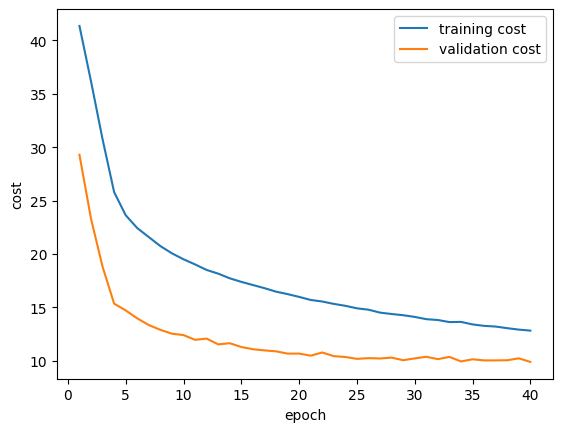

In [40]:
plt.plot(range(1, len(train_costs) + 1), train_costs, label="training cost")
plt.plot(range(1, len(valid_costs) + 1), valid_costs, label="validation cost")
plt.xlabel("epoch")
plt.ylabel("cost")
plt.legend()
plt.show()

The above training graph shows the training and validation costs over the epochs. We can see that both decrease in a smooth manner, indicating that the model is learning effectively as it progresses down the gradient. Further training is not required at this point, as the training cost is still falling while the validation cost has plateaued, suggesting that additional epochs may not yield significant improvements.

In [41]:

# This save is done after best_model_state is loaded into the model to ensure the best weights are saved
model.save_pretrained(data_dir / "runs" / "rtdetr_cghd") # save the restored parameters and the class name maps so the model can be loaded later with from_pretrained

# from_pretrained is a Hugging Face method. It loads a model previously saved with save_pretrained.
# The folder already contains the class name maps, so they do not need to be passed again:
# model = RTDetrForObjectDetection.from_pretrained(data_dir / "runs" / "rtdetr_cghd")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Evaluation:

### Load model


In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model = RTDetrForObjectDetection.from_pretrained(data_dir / "runs" / "rtdetr_cghd") # load the saved fine-tuned model, including the class name maps
model.to(device)
model.eval()


### Test predictions


In [ ]:
predictions = []
ground_truths = []
sample_images = []
with torch.no_grad():
    for images, targets in test_loader:
        outputs = model(pixel_values=images.to(device)) # no labels, so this is inference
        confidence, class_ids = outputs.logits.sigmoid().max(dim=-1) # highest sigmoid score of the class linear layer, and which class it was
        for index, target in enumerate(targets):
            predictions.append({
                "scores": confidence[index].cpu(),
                "labels": class_ids[index].cpu(),
                "boxes": outputs.pred_boxes[index].cpu(), # normalized center_x, center_y, width, height
            })
            ground_truths.append({
                "labels": target["class_labels"].cpu(),
                "boxes": target["boxes"].cpu(),
            })
            if len(sample_images) < 5:
                sample_images.append(images[index].cpu())

print(len(predictions), "test images")


### Per-class average precision


In [ ]:
iou_threshold = 0.5 # intersection over union. Above 0.5 we count the boxes as the same object, otherwise the prediction is wrong
n_classes = len(label_encoder.classes_)
average_precisions = []

for class_id in range(n_classes): # one class at a time
    pairs = [] # (confidence, was it correct) for this class, across the test set
    n_ground_truth = 0
    for prediction, ground_truth in zip(predictions, ground_truths):
        ground_truth_boxes = ground_truth["boxes"][ground_truth["labels"] == class_id]
        prediction_boxes = prediction["boxes"][prediction["labels"] == class_id]
        scores = prediction["scores"][prediction["labels"] == class_id]
        n_ground_truth += len(ground_truth_boxes)
        if len(prediction_boxes) == 0:
            continue
        prediction_corners = torchvision.ops.box_convert(prediction_boxes, in_fmt="cxcywh", out_fmt="xyxy")
        matched = torch.zeros(len(ground_truth_boxes), dtype=torch.bool)
        overlaps = None
        if len(ground_truth_boxes):
            ground_truth_corners = torchvision.ops.box_convert(ground_truth_boxes, in_fmt="cxcywh", out_fmt="xyxy")
            overlaps = torchvision.ops.box_iou(prediction_corners, ground_truth_corners) # overlap is the same either way round
        for index in scores.argsort(descending=True).tolist(): # highest confidence first, then we walk down the list
            true_positive = False
            if overlaps is not None:
                overlap = overlaps[index].clone()
                overlap[matched] = -1 # a ground-truth box can only be matched once
                best = int(overlap.argmax())
                if overlap[best] >= iou_threshold: # overlap above 0.5, so this prediction is correct
                    matched[best] = True
                    true_positive = True
            pairs.append((float(scores[index]), true_positive)) # correct or not, it still counts as one of our predictions

    if n_ground_truth == 0: # this class is not in the test set
        average_precisions.append(np.nan)
        continue
    if len(pairs) == 0:
        average_precisions.append(0.0)
        continue
    pairs.sort(key=lambda pair: -pair[0]) # whole class in confidence order, not just one image
    true_positives = np.cumsum([1 if hit else 0 for _, hit in pairs])
    false_positives = np.cumsum([0 if hit else 1 for _, hit in pairs])
    precision = true_positives / (true_positives + false_positives) # of the predictions so far, how many were correct
    recall = true_positives / n_ground_truth # of this class's ground-truth boxes, how many we have found so far
    recall_steps = np.concatenate(([0.0], recall, [1.0]))
    precision_steps = np.concatenate(([0.0], precision, [0.0]))
    for index in range(len(precision_steps) - 1, 0, -1): # precision steps down as more wrong boxes get included
        precision_steps[index - 1] = max(precision_steps[index - 1], precision_steps[index])
    changes = np.where(recall_steps[1:] != recall_steps[:-1])[0]
    average_precisions.append(np.sum((recall_steps[changes + 1] - recall_steps[changes]) * precision_steps[changes + 1])) # area under this class's precision-recall curve

average_precisions = np.array(average_precisions)
missing = [label_encoder.classes_[i] for i, score in enumerate(average_precisions) if np.isnan(score)]
print("not in the test set:", ", ".join(missing) if missing else "none")

plt.figure(figsize=(14, 4))
sns.barplot(x=np.arange(n_classes), y=np.nan_to_num(average_precisions))
plt.xticks(range(n_classes), label_encoder.classes_, rotation=90)
plt.ylabel("average precision")
plt.xlabel("class")
plt.tight_layout()
plt.show()


### Mean average precision


In [ ]:
print(f"mAP@0.5 {np.nanmean(average_precisions):.3f}") # average the per-class areas. That average is the mean average precision

map_over_iou = []
for iou_threshold in np.arange(0.5, 1.0, 0.05): # same walk as above, redone at a tighter overlap each time (0.50, 0.55, ... 0.95)
    class_scores = []
    for class_id in range(n_classes): # one class at a time, then we average the areas
        pairs = []
        n_ground_truth = 0
        for prediction, ground_truth in zip(predictions, ground_truths):
            ground_truth_boxes = ground_truth["boxes"][ground_truth["labels"] == class_id]
            prediction_boxes = prediction["boxes"][prediction["labels"] == class_id]
            scores = prediction["scores"][prediction["labels"] == class_id]
            n_ground_truth += len(ground_truth_boxes)
            if len(prediction_boxes) == 0:
                continue
            prediction_corners = torchvision.ops.box_convert(prediction_boxes, in_fmt="cxcywh", out_fmt="xyxy")
            matched = torch.zeros(len(ground_truth_boxes), dtype=torch.bool)
            overlaps = None
            if len(ground_truth_boxes):
                ground_truth_corners = torchvision.ops.box_convert(ground_truth_boxes, in_fmt="cxcywh", out_fmt="xyxy")
                overlaps = torchvision.ops.box_iou(prediction_corners, ground_truth_corners)
            for index in scores.argsort(descending=True).tolist(): # highest confidence first
                true_positive = False
                if overlaps is not None:
                    overlap = overlaps[index].clone()
                    overlap[matched] = -1
                    best = int(overlap.argmax())
                    if overlap[best] >= iou_threshold: # above this overlap, the prediction is correct
                        matched[best] = True
                        true_positive = True
                pairs.append((float(scores[index]), true_positive))
        if n_ground_truth == 0 or len(pairs) == 0:
            if n_ground_truth > 0:
                class_scores.append(0.0)
            continue
        pairs.sort(key=lambda pair: -pair[0])
        true_positives = np.cumsum([1 if hit else 0 for _, hit in pairs])
        false_positives = np.cumsum([0 if hit else 1 for _, hit in pairs])
        precision = true_positives / (true_positives + false_positives) # of the predictions so far, how many were correct
        recall = true_positives / n_ground_truth # of this class's ground-truth boxes, how many we have found so far
        recall_steps = np.concatenate(([0.0], recall, [1.0]))
        precision_steps = np.concatenate(([0.0], precision, [0.0]))
        for index in range(len(precision_steps) - 1, 0, -1):
            precision_steps[index - 1] = max(precision_steps[index - 1], precision_steps[index])
        changes = np.where(recall_steps[1:] != recall_steps[:-1])[0]
        class_scores.append(np.sum((recall_steps[changes + 1] - recall_steps[changes]) * precision_steps[changes + 1])) # area under this class's curve
    map_over_iou.append(np.mean(class_scores)) # average the class areas at this overlap

print(f"mAP@0.5:0.95 {np.mean(map_over_iou):.3f}") # then average those means across the tighter overlaps


### Confusion matrix


In [ ]:
iou_threshold = 0.5
score_threshold = 0.5 # queries below this confidence are left out
n_classes = len(label_encoder.classes_)
confusion = np.zeros((n_classes + 1, n_classes + 1), dtype=int)
background = n_classes

for prediction, ground_truth in zip(predictions, ground_truths):
    keep = prediction["scores"] >= score_threshold
    prediction_boxes = prediction["boxes"][keep]
    prediction_labels = prediction["labels"][keep]
    prediction_scores = prediction["scores"][keep]
    ground_truth_boxes = ground_truth["boxes"]
    ground_truth_labels = ground_truth["labels"]
    matched = set()
    overlaps = None
    if len(prediction_boxes) and len(ground_truth_boxes):
        prediction_corners = torchvision.ops.box_convert(prediction_boxes, in_fmt="cxcywh", out_fmt="xyxy")
        ground_truth_corners = torchvision.ops.box_convert(ground_truth_boxes, in_fmt="cxcywh", out_fmt="xyxy")
        overlaps = torchvision.ops.box_iou(prediction_corners, ground_truth_corners)
    for index in prediction_scores.argsort(descending=True).tolist():
        if overlaps is None:
            confusion[background, int(prediction_labels[index])] += 1 # prediction with no ground-truth box to match
            continue
        overlap = overlaps[index].clone()
        for seen in matched:
            overlap[seen] = -1
        best = int(overlap.argmax())
        if overlap[best] >= iou_threshold:
            matched.add(best)
            confusion[int(ground_truth_labels[best]), int(prediction_labels[index])] += 1 # row is the true class, column is the predicted class
        else:
            confusion[background, int(prediction_labels[index])] += 1
    for index in range(len(ground_truth_labels)):
        if index not in matched:
            confusion[int(ground_truth_labels[index]), background] += 1 # ground-truth box the model missed

names = list(label_encoder.classes_) + ["background"]
plt.figure(figsize=(14, 12))
ax = sns.heatmap(confusion, xticklabels=names, yticklabels=names, cmap="Blues")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
plt.tight_layout()
plt.show()


### Precision-recall curve


In [ ]:
iou_threshold = 0.5
n_classes = len(label_encoder.classes_)
pairs = []
n_ground_truth = 0

for class_id in range(n_classes):
    for prediction, ground_truth in zip(predictions, ground_truths):
        ground_truth_boxes = ground_truth["boxes"][ground_truth["labels"] == class_id]
        prediction_boxes = prediction["boxes"][prediction["labels"] == class_id]
        scores = prediction["scores"][prediction["labels"] == class_id]
        n_ground_truth += len(ground_truth_boxes)
        if len(prediction_boxes) == 0:
            continue
        prediction_corners = torchvision.ops.box_convert(prediction_boxes, in_fmt="cxcywh", out_fmt="xyxy")
        matched = torch.zeros(len(ground_truth_boxes), dtype=torch.bool)
        overlaps = None
        if len(ground_truth_boxes):
            ground_truth_corners = torchvision.ops.box_convert(ground_truth_boxes, in_fmt="cxcywh", out_fmt="xyxy")
            overlaps = torchvision.ops.box_iou(prediction_corners, ground_truth_corners)
        for index in scores.argsort(descending=True).tolist():
            true_positive = False
            if overlaps is not None:
                overlap = overlaps[index].clone()
                overlap[matched] = -1
                best = int(overlap.argmax())
                if overlap[best] >= iou_threshold:
                    matched[best] = True
                    true_positive = True
            pairs.append((float(scores[index]), true_positive))

pairs.sort(key=lambda pair: -pair[0]) # highest confidence first, across every class
true_positives = np.cumsum([1 if hit else 0 for _, hit in pairs])
false_positives = np.cumsum([0 if hit else 1 for _, hit in pairs])
precision = true_positives / (true_positives + false_positives)
recall = true_positives / n_ground_truth

plt.plot(recall, precision)
plt.xlabel("recall")
plt.ylabel("precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


### Sample predictions


In [ ]:
def predict(image):
    # one new page. It has no boxes, so only the image goes through the same transforms
    if not isinstance(image, Image.Image):
        image = ImageOps.exif_transpose(Image.open(image)).convert("RGB") # same open as the dataset
    image = standard_transforms(image).unsqueeze(0) # 640x640 and ImageNet normalize, then a batch of one
    with torch.no_grad():
        outputs = model(pixel_values=image.to(device))
    confidence, class_ids = outputs.logits.sigmoid().max(dim=-1) # highest sigmoid score of the class linear layer, and which class it was
    keep = confidence[0] >= 0.5 # drop queries below the confidence we draw on the sample images
    return {
        "scores": confidence[0][keep].cpu(),
        "labels": class_ids[0][keep].cpu(),
        "boxes": outputs.pred_boxes[0][keep].cpu(), # normalized center_x, center_y, width, height
    }


In [ ]:
from matplotlib.patches import Rectangle

score_threshold = 0.5
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1) # ImageNet mean used in preprocess
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
figure, axes = plt.subplots(5, 1, figsize=(8, 24))
for axis, image, prediction, ground_truth in zip(axes, sample_images, predictions, ground_truths):
    picture = (image * std + mean).clamp(0, 1) # undo the ImageNet normalization so the page is visible
    axis.imshow(picture.permute(1, 2, 0).numpy())
    ground_truth_corners = torchvision.ops.box_convert(ground_truth["boxes"], in_fmt="cxcywh", out_fmt="xyxy") * 640
    for box in ground_truth_corners:
        x1, y1, x2, y2 = box.tolist()
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1)) # ground truth
    keep = prediction["scores"] >= score_threshold
    prediction_corners = torchvision.ops.box_convert(prediction["boxes"][keep], in_fmt="cxcywh", out_fmt="xyxy") * 640
    for box, label, score in zip(prediction_corners, prediction["labels"][keep], prediction["scores"][keep]):
        x1, y1, x2, y2 = box.tolist()
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1)) # prediction
        axis.text(x1, y1, f"{label_encoder.classes_[int(label)]} {float(score):.2f}", color="red", fontsize=6)
    axis.axis("off")
plt.tight_layout()
plt.show()
